### **Cell 1 - Imports**

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

### **Cell 2 - Configure file locations**

In [14]:
DATA_DIR = Path("data")

COLLISIONS_FILE = DATA_DIR / "dft-road-casualty-statistics-collision-last-5-years.csv"
VEHICLES_FILE = DATA_DIR / "dft-road-casualty-statistics-vehicle-last-5-years.csv"
CASUALTIES_FILE = DATA_DIR / "dft-road-casualty-statistics-casualty-last-5-years.csv"

In [11]:
!pwd

/Users/davidbird/Library/Mobile Documents/com~apple~CloudDocs/analysis/snowflake


### **Cell 3 - Load data**

In [13]:
from pathlib import Path

data_dir = Path("data")

print(data_dir.exists())
print(list(data_dir.glob("*")))

True
[PosixPath('data/dft-road-casualty-statistics-casualty-last-5-years.csv'), PosixPath('data/dft-road-casualty-statistics-vehicle-last-5-years.csv'), PosixPath('data/dft-road-casualty-statistics-collision-last-5-years.csv')]


In [15]:
collisions = pd.read_csv(
    COLLISIONS_FILE,
    low_memory=False
)

vehicles = pd.read_csv(
    VEHICLES_FILE,
    low_memory=False
)

casualties = pd.read_csv(
    CASUALTIES_FILE,
    low_memory=False
)

print("Loaded successfully")

Loaded successfully


### **Cell 4 - Basic dimensions**

In [17]:
datasets = {
    "collisions": collisions,
    "vehicles": vehicles,
    "casualties": casualties
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("-" * 40)
    print(f"Rows    : {len(df):,}")
    print(f"Columns : {len(df.columns)}")


COLLISIONS
----------------------------------------
Rows    : 513,801
Columns : 44

VEHICLES
----------------------------------------
Rows    : 937,265
Columns : 32

CASUALTIES
----------------------------------------
Rows    : 652,821
Columns : 24


### **Cell 5 - See the first records**

In [18]:
collisions.head()

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,1,03/10/2024,5,16:06,-1,E06000001,E06000001,E06000001,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,1,1,1,-1,-1,0,1,1,2,E01012005,7,1,1.0,0.0
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,1,29/11/2025,7,16:34,-1,E06000002,E06000002,E06000002,3,171,6,30,-1,13,4,6,0,-1,-1,0,4,1,1,-1,-1,0,1,1,2,E01012090,6,1,1.0,0.0
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,3,01/06/2025,1,22:07,-1,E06000003,E06000003,E06000003,3,1042,6,30,-1,13,4,6,0,-1,-1,0,4,1,1,-1,-1,0,1,1,2,E01032560,3,1,0.0,1.0
3,202417S104724,2024,17S104724,440460.0,517548.0,-1.37599,54.55157,17,3,2,2,20/04/2024,7,14:40,-1,E06000004,E06000004,E06000004,3,66,3,60,-1,0,-1,-1,-1,-1,-1,0,1,1,1,-1,-1,0,2,1,1,E01012269,3,1,0.0,1.0
4,202517S106525,2025,17S106525,444331.0,518776.0,-1.31596,54.56228,17,2,2,1,16/05/2025,6,07:25,-1,E06000004,E06000004,E06000004,6,0,6,30,-1,13,4,6,0,-1,-1,0,1,1,1,-1,-1,0,1,1,2,E01035199,7,1,1.0,0.0


In [19]:
vehicles.head()

,collision_index,collision_year,collision_ref_no,vehicle_reference,vehicle_type,towing_and_articulation,vehicle_manoeuvre_historic,vehicle_manoeuvre,vehicle_direction_from,vehicle_direction_to,vehicle_location_restricted_lane_historic,vehicle_location_restricted_lane,junction_location,skidding_and_overturning,hit_object_in_carriageway,vehicle_leaving_carriageway,hit_object_off_carriageway,first_point_of_impact,vehicle_left_hand_drive,journey_purpose_of_driver_historic,journey_purpose_of_driver,sex_of_driver,age_of_driver,age_band_of_driver,engine_capacity_cc,propulsion_code,age_of_vehicle,generic_make_model,driver_imd_decile,lsoa_of_driver,escooter_flag,driver_distance_banding
0,2021622100736,2021,622100736,1,9,0,18,19,2,6,0,0,1,0,0,0,0,4,1,6,6,1,35,6,1998,2,10,CHEVROLET CRUZE,4,W01000966,0,-1
1,2021010319369,2021,010319369,1,9,9,99,99,9,9,99,99,9,9,99,9,99,9,9,6,6,1,25,5,1598,1,9,CHEVROLET CRUZE,2,E01002078,0,-1
2,2021122100703,2021,122100703,2,9,0,2,2,0,0,0,0,2,0,0,0,0,2,1,6,6,1,50,8,1796,1,11,CHEVROLET CRUZE,7,E01027646,0,-1
3,2021471117441,2021,471117441,1,9,0,5,5,1,7,9,9,2,0,0,0,0,1,1,1,1,1,28,6,1598,1,7,CHEVROLET CRUZE,6,E01031513,0,-1
4,2021451064862,2021,451064862,1,9,0,3,3,2,6,0,0,1,0,0,0,0,2,1,3,7,2,28,6,1598,1,9,CHEVROLET CRUZE,8,E01030972,0,-1


In [20]:
casualties.head()

,collision_index,collision_year,collision_ref_no,vehicle_reference,casualty_reference,casualty_class,sex_of_casualty,age_of_casualty,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_imd_decile,lsoa_of_casualty,enhanced_casualty_severity,casualty_injury_based,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,casualty_distance_banding,escooter_flag
0,2022522205219,2022,522205219,2,1,1,1,20,4,2,0,0,0,0,0,-1,4,E01033362,-1,0,1.0,0.0,-1,0
1,2021010288881,2021,010288881,1,1,3,2,7,2,2,9,6,0,0,0,0,1,E01004340,-1,0,1.0,0.0,-1,0
2,2021010288939,2021,010288939,1,1,3,1,21,5,3,8,4,0,0,0,0,3,E01001823,-1,0,0.0,1.0,-1,0
3,2021010289554,2021,010289554,1,1,3,2,11,3,3,5,1,0,0,0,0,2,E01000931,-1,0,0.0,1.0,-1,0
4,2021010290262,2021,010290262,1,1,3,2,31,6,2,5,1,0,0,0,0,6,E01003226,-1,0,1.0,0.0,-1,0


### **Cell 6 - Column names**

In [21]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.columns.tolist())


COLLISIONS
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 'collision_inj

### **Cell 7 - Data types**

In [22]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    display(df.dtypes)


COLLISIONS


collision_index                                      object
collision_year                                        int64
collision_ref_no                                     object
location_easting_osgr                               float64
location_northing_osgr                              float64
longitude                                           float64
latitude                                            float64
police_force                                          int64
collision_severity                                    int64
number_of_vehicles                                    int64
number_of_casualties                                  int64
date                                                 object
day_of_week                                           int64
time                                                 object
local_authority_district                              int64
local_authority_ons_district                         object
local_authority_highway                 


VEHICLES


collision_index                              object
collision_year                                int64
collision_ref_no                             object
vehicle_reference                             int64
vehicle_type                                  int64
towing_and_articulation                       int64
vehicle_manoeuvre_historic                    int64
vehicle_manoeuvre                             int64
vehicle_direction_from                        int64
vehicle_direction_to                          int64
vehicle_location_restricted_lane_historic     int64
vehicle_location_restricted_lane              int64
junction_location                             int64
skidding_and_overturning                      int64
hit_object_in_carriageway                     int64
vehicle_leaving_carriageway                   int64
hit_object_off_carriageway                    int64
first_point_of_impact                         int64
vehicle_left_hand_drive                       int64
journey_purp


CASUALTIES


collision_index                        object
collision_year                          int64
collision_ref_no                       object
vehicle_reference                       int64
casualty_reference                      int64
casualty_class                          int64
sex_of_casualty                         int64
age_of_casualty                         int64
age_band_of_casualty                    int64
casualty_severity                       int64
pedestrian_location                     int64
pedestrian_movement                     int64
car_passenger                           int64
bus_or_coach_passenger                  int64
pedestrian_road_maintenance_worker      int64
casualty_type                           int64
casualty_imd_decile                     int64
lsoa_of_casualty                       object
enhanced_casualty_severity              int64
casualty_injury_based                   int64
casualty_adjusted_severity_serious    float64
casualty_adjusted_severity_slight 

### **Cell 8 - Missing values**

In [23]:
for name, df in datasets.items():

    missing = (
        df.isna()
          .sum()
          .sort_values(ascending=False)
          .reset_index()
    )

    missing.columns = ["column", "null_count"]

    missing["null_pct"] = (
        missing["null_count"] / len(df)
    ).round(4) * 100

    print(f"\n{name.upper()}")
    display(missing.head(20))


COLLISIONS


,column,null_count,null_pct
0,location_easting_osgr,53,0.01
1,location_northing_osgr,53,0.01
2,longitude,53,0.01
3,latitude,53,0.01
4,collision_index,0,0.00
5,carriageway_hazards_historic,0,0.00
6,second_road_number,0,0.00
7,pedestrian_crossing_human_control_historic,0,0.00
8,pedestrian_crossing_physical_facilities_historic,0,0.00
9,pedestrian_crossing,0,0.00



VEHICLES


,column,null_count,null_pct
0,collision_index,0,0.0
1,collision_year,0,0.0
2,escooter_flag,0,0.0
3,lsoa_of_driver,0,0.0
4,driver_imd_decile,0,0.0
5,generic_make_model,0,0.0
6,age_of_vehicle,0,0.0
7,propulsion_code,0,0.0
8,engine_capacity_cc,0,0.0
9,age_band_of_driver,0,0.0



CASUALTIES


,column,null_count,null_pct
0,collision_index,0,0.0
1,collision_year,0,0.0
2,casualty_distance_banding,0,0.0
3,casualty_adjusted_severity_slight,0,0.0
4,casualty_adjusted_severity_serious,0,0.0
5,casualty_injury_based,0,0.0
6,enhanced_casualty_severity,0,0.0
7,lsoa_of_casualty,0,0.0
8,casualty_imd_decile,0,0.0
9,casualty_type,0,0.0


### **Cell 9 - Locate join keys**

In [26]:
#accident_index


In [25]:
for name, df in datasets.items():

    print(
        name,
        "accident_index" in [c.lower() for c in df.columns]
    )

collisions False
vehicles False
casualties False


### **Cell 10 - Collision uniqueness check**

In [29]:
collisions.columns.tolist()

['collision_index',
 'collision_year',
 'collision_ref_no',
 'location_easting_osgr',
 'location_northing_osgr',
 'longitude',
 'latitude',
 'police_force',
 'collision_severity',
 'number_of_vehicles',
 'number_of_casualties',
 'date',
 'day_of_week',
 'time',
 'local_authority_district',
 'local_authority_ons_district',
 'local_authority_highway',
 'local_authority_highway_current',
 'first_road_class',
 'first_road_number',
 'road_type',
 'speed_limit',
 'junction_detail_historic',
 'junction_detail',
 'junction_control',
 'second_road_class',
 'second_road_number',
 'pedestrian_crossing_human_control_historic',
 'pedestrian_crossing_physical_facilities_historic',
 'pedestrian_crossing',
 'light_conditions',
 'weather_conditions',
 'road_surface_conditions',
 'special_conditions_at_site',
 'carriageway_hazards_historic',
 'carriageway_hazards',
 'urban_or_rural_area',
 'did_police_officer_attend_scene_of_accident',
 'trunk_road_flag',
 'lsoa_of_accident_location',
 'enhanced_severit

In [31]:
collisions["collision_index"].nunique()

513801

In [28]:
len(collisions)

513801

### **Cell 11 - One-to-many relationship checks**

In [33]:
vehicles_per_accident = (
    vehicles.groupby("collision_index")
            .size()
            .describe()
)

vehicles_per_accident

count    513801.000000
mean          1.824179
std           0.687802
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max          26.000000
dtype: float64

In [34]:
casualties_per_accident = (
    casualties.groupby("collision_index")
              .size()
              .describe()
)

casualties_per_accident


count    513801.000000
mean          1.270572
std           0.726348
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         142.000000
dtype: float64

### **Cell 12 - Referential integrity**

In [35]:
missing_vehicles = (
    ~vehicles["collision_index"]
        .isin(collisions["collision_index"])
).sum()

missing_vehicles

np.int64(0)

In [36]:
missing_casualties = (
    ~casualties["collision_index"]
        .isin(collisions["collision_index"])
).sum()

missing_casualties

np.int64(0)

### **Cell 13 - Inspect collision years**

In [37]:
[c for c in collisions.columns if "date" in c.lower()]

['date']

In [41]:
collisions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   513801 non-null  object 
 1   collision_year                                    513801 non-null  int64  
 2   collision_ref_no                                  513801 non-null  object 
 3   location_easting_osgr                             513748 non-null  float64
 4   location_northing_osgr                            513748 non-null  float64
 5   longitude                                         513748 non-null  float64
 6   latitude                                          513748 non-null  float64
 7   police_force                                      513801 non-null  int64  
 8   collision_severity                                513801 non-null  int64  
 9   numb

In [42]:
collisions["date"] = pd.to_datetime(
    collisions["date"],
    dayfirst=True,
    errors="coerce"
)


In [43]:
collisions["date"].dt.year.value_counts().sort_index()

date
2021    101087
2022    106004
2023    104258
2024    100927
2025    101525
Name: count, dtype: int64

### **Cell 14 - Severity distribution**

In [44]:
severity_cols = [
    c for c in collisions.columns
    if "severity" in c.lower()
]

severity_cols

['collision_severity',
 'enhanced_severity_collision',
 'collision_adjusted_severity_serious',
 'collision_adjusted_severity_slight']

In [46]:
collisions["collision_severity"].value_counts()

collision_severity
3    389435
2    116813
1      7553
Name: count, dtype: int64

### **Cell 15 - Top vehicle types**

In [47]:
[c for c in vehicles.columns if "vehicle" in c.lower()]

['vehicle_reference',
 'vehicle_type',
 'vehicle_manoeuvre_historic',
 'vehicle_manoeuvre',
 'vehicle_direction_from',
 'vehicle_direction_to',
 'vehicle_location_restricted_lane_historic',
 'vehicle_location_restricted_lane',
 'vehicle_leaving_carriageway',
 'vehicle_left_hand_drive',
 'age_of_vehicle']

In [48]:
vehicles["vehicle_type"].value_counts().head(20)

vehicle_type
 9     637681
 1      81486
 19     60309
 3      44795
 5      23011
 8      15362
 11     15100
 21     13247
 4       9590
 33      6901
 90      5094
 2       5008
 20      4046
 98      3920
 97      2988
 17      1937
 23      1902
 22      1628
 10      1506
-1        661
Name: count, dtype: int64

### **Cell 16 - Build a joined sample**

This is extremely useful before Snowflake.

In [51]:
sample = (
    collisions
        .merge(
            vehicles,
            on="collision_index",
            how="left"
        )
        .merge(
            casualties,
            on="collision_index",
            how="left"
        )
)


In [52]:
sample.shape

(1241682, 98)

### **Cell 17 - Analytical questions**

<Axes: title={'center': 'Collisions by Year'}, xlabel='date'>

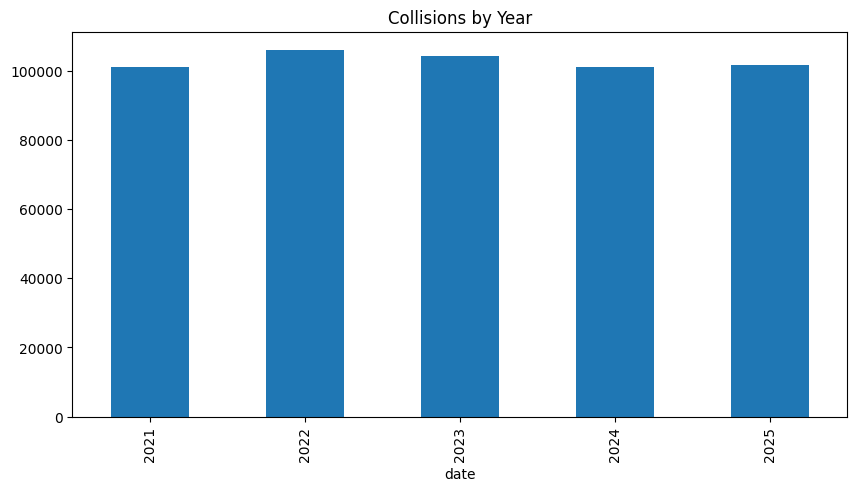

In [55]:
(
    collisions["date"]
    .dt.year
    .value_counts()
    .sort_index()
    .plot(
        kind="bar",
        figsize=(10,5),
        title="Collisions by Year"
    )
)

### **Cell 18 - Data dictionary**

In [56]:
dictionary = []

for name, df in datasets.items():

    for col in df.columns:

        dictionary.append({
            "table": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "nulls": int(df[col].isna().sum())
        })

dictionary = pd.DataFrame(dictionary)

dictionary.head()

,table,column,dtype,nulls
0,collisions,collision_index,object,0
1,collisions,collision_year,int64,0
2,collisions,collision_ref_no,object,0
3,collisions,location_easting_osgr,float64,53
4,collisions,location_northing_osgr,float64,53


### **Cell 19 - Export profiling results**

In [57]:
dictionary.to_csv(
    "data_dictionary.csv",
    index=False
)

In [58]:
collisions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513801 entries, 0 to 513800
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype         
---  ------                                            --------------   -----         
 0   collision_index                                   513801 non-null  object        
 1   collision_year                                    513801 non-null  int64         
 2   collision_ref_no                                  513801 non-null  object        
 3   location_easting_osgr                             513748 non-null  float64       
 4   location_northing_osgr                            513748 non-null  float64       
 5   longitude                                         513748 non-null  float64       
 6   latitude                                          513748 non-null  float64       
 7   police_force                                      513801 non-null  int64         
 8   collision_seve

In [59]:
vehicles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 937265 entries, 0 to 937264
Data columns (total 32 columns):
 #   Column                                     Non-Null Count   Dtype 
---  ------                                     --------------   ----- 
 0   collision_index                            937265 non-null  object
 1   collision_year                             937265 non-null  int64 
 2   collision_ref_no                           937265 non-null  object
 3   vehicle_reference                          937265 non-null  int64 
 4   vehicle_type                               937265 non-null  int64 
 5   towing_and_articulation                    937265 non-null  int64 
 6   vehicle_manoeuvre_historic                 937265 non-null  int64 
 7   vehicle_manoeuvre                          937265 non-null  int64 
 8   vehicle_direction_from                     937265 non-null  int64 
 9   vehicle_direction_to                       937265 non-null  int64 
 10  vehicle_location_res

casualties.info()

### **Step 1: Design the Snowflake architecture**

### **Step 2: Decide your business questions**

Don't load data without knowing what you'll answer.

I'd suggest:

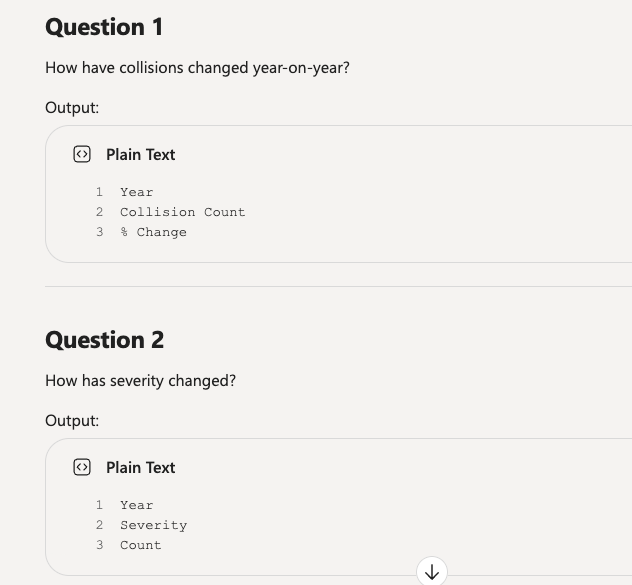

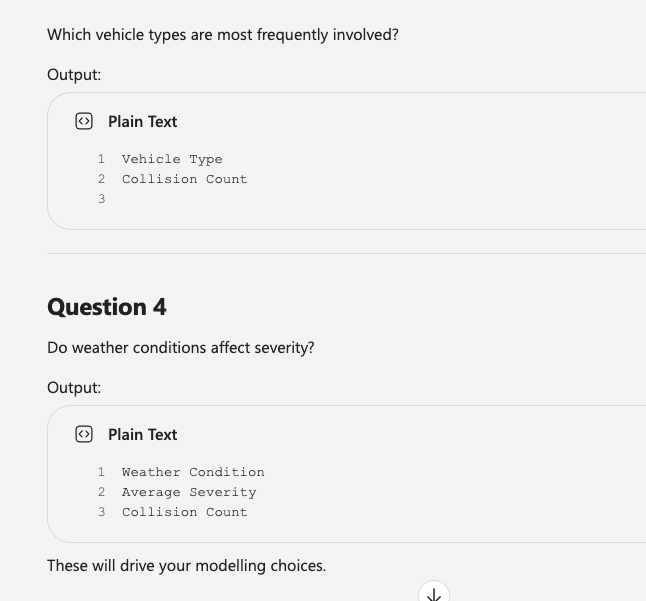

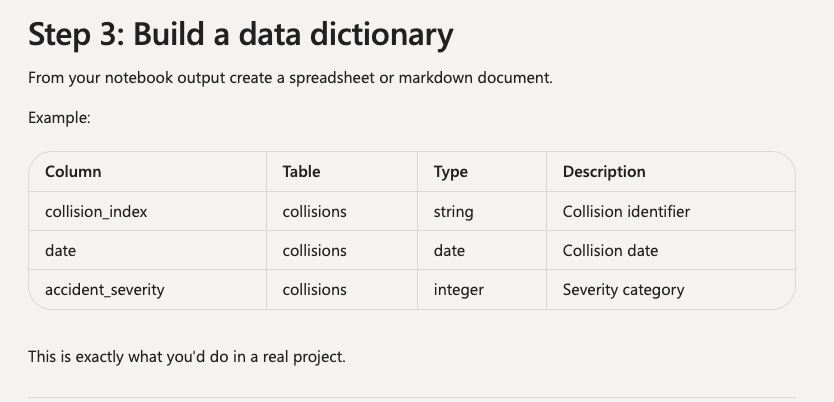

### **Step 4: Create your Snowflake account**

If you haven't already:

Create Trial Account
Open Snowsight
Create warehouse